<a href="https://colab.research.google.com/github/Deadwars/etective-senales-deep-learning/blob/main/detective_senales_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:


import numpy as np


import scipy.signal as signal

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split


np.random.seed(42)

print("¡Paso 1 completado! Todas las librerías necesarias se cargaron con éxito.")


¡Paso 1 completado! Todas las librerías necesarias se cargaron con éxito.


In [2]:

fs = 1000.0
fc = 100.0
Rs = 20.0
num_symbols = 10

t_symbol = 1 / Rs
t_total = num_symbols * t_symbol

t = np.arange(0, t_total, 1 / fs)
num_samples_per_signal = len(t)

print("¡Paso 2 completado!")
print(f"Cada señal durará exactamente {t_total} segundos.")
print(f"Cada señal estará compuesta por una cadena de {num_samples_per_signal} puntos digitales.")


¡Paso 2 completado!
Cada señal durará exactamente 0.5 segundos.
Cada señal estará compuesta por una cadena de 500 puntos digitales.


In [3]:


def generar_ask(t, fs, fc, Rs, num_symbols):
    """Genera una señal ASK (Cambia el tamaño/amplitud de la onda según el bit)"""
    bits = np.random.randint(0, 2, num_symbols)
    muestras_por_simbolo = int(fs / Rs)
    moduladora = np.repeat(bits, muestras_por_simbolo)[:len(t)]
    portadora = np.cos(2 * np.pi * fc * t)
    return moduladora * portadora

def generar_fsk(t, fs, fc, Rs, num_symbols):
    """Genera una señal FSK (Cambia la velocidad/frecuencia de la onda según el bit)"""
    bits = np.random.randint(0, 2, num_symbols)
    muestras_por_simbolo = int(fs / Rs)
    f1 = fc - 30
    f2 = fc + 30

    frecuencias = np.where(bits == 1, f2, f1)
    frec_modulada = np.repeat(frecuencias, muestras_por_simbolo)[:len(t)]


    fase_acumulada = np.cumsum(2 * np.pi * frec_modulada / fs)
    return np.cos(fase_acumulada)

def generar_psk(t, fs, fc, Rs, num_symbols):
    """Genera una señal PSK (Invierte el sentido de la onda/fase según el bit)"""
    bits = np.random.randint(0, 2, num_symbols)
    muestras_por_simbolo = int(fs / Rs)
    fases = np.where(bits == 1, np.pi, 0)
    fase_modulada = np.repeat(fases, muestras_por_simbolo)[:len(t)]
    return np.cos(2 * np.pi * fc * t + fase_modulada)

def generar_16qam(t, fs, fc, Rs, num_symbols):
    """Genera una señal 16-QAM (Modulación avanzada combinando 16 posiciones de Amplitud y Fase)"""
    valores_posibles = np.array([-3, -1, 1, 3])
    I_symbols = np.random.choice(valores_posibles, num_symbols)
    Q_symbols = np.random.choice(valores_posibles, num_symbols)

    muestras_por_simbolo = int(fs / Rs)
    I_mod = np.repeat(I_symbols, muestras_por_simbolo)[:len(t)]
    Q_mod = np.repeat(Q_symbols, muestras_por_simbolo)[:len(t)]

    return I_mod * np.cos(2 * np.pi * fc * t) - Q_mod * np.sin(2 * np.pi * fc * t)

print("¡Paso 3 completado! Las 4 fábricas de señales matemáticas están listas para usarse.")


¡Paso 3 completado! Las 4 fábricas de señales matemáticas están listas para usarse.


In [4]:

def anadir_ruido_awgn(senal, snr_db):
    """Añade interferencia de estática a la señal basándose en la potencia deseada (SNR en dB)"""
    potencia_senal = np.mean(senal ** 2)
    snr_lineal = 10 ** (snr_db / 10.0)
    potencia_ruido = potencia_senal / snr_lineal


    ruido = np.random.normal(0, np.sqrt(potencia_ruido), len(senal))
    return senal + ruido

print("¡Paso 4 completado! Simulador de ruido de canal listo.")


¡Paso 4 completado! Simulador de ruido de canal listo.


In [5]:

muestras_por_tipo = 1000
modulaciones = ['ASK', 'FSK', 'PSK', 'QAM']

X = []
y = []

niveles_snr = np.linspace(5, 25, 10)


for idx, tipo in enumerate(modulaciones):
    for _ in range(muestras_por_tipo):

        if tipo == 'ASK':
            senal_pura = generar_ask(t, fs, fc, Rs, num_symbols)
        elif tipo == 'FSK':
            senal_pura = generar_fsk(t, fs, fc, Rs, num_symbols)
        elif tipo == 'PSK':
            senal_pura = generar_psk(t, fs, fc, Rs, num_symbols)
        elif tipo == 'QAM':
            senal_pura = generar_16qam(t, fs, fc, Rs, num_symbols)


        snr_elegido = np.random.choice(niveles_snr)
        senal_con_ruido = anadir_ruido_awgn(senal_pura, snr_elegido)


        X.append(senal_con_ruido)
        y.append(idx)

X = np.array(X)
y = np.array(y)

print("¡Paso 5 completado! El almacén de datos (Dataset) se ha llenado.")
print(f"Estructura del almacén de señales (X): {X.shape}  Significa: 4,000 señales de {X.shape[1]} puntos cada una.")
print(f"Estructura del almacén de etiquetas (y): {y.shape}  Contiene 4,000 respuestas correctas.")


¡Paso 5 completado! El almacén de datos (Dataset) se ha llenado.
Estructura del almacén de señales (X): (4000, 500)  Significa: 4,000 señales de 500 puntos cada una.
Estructura del almacén de etiquetas (y): (4000,)  Contiene 4,000 respuestas correctas.


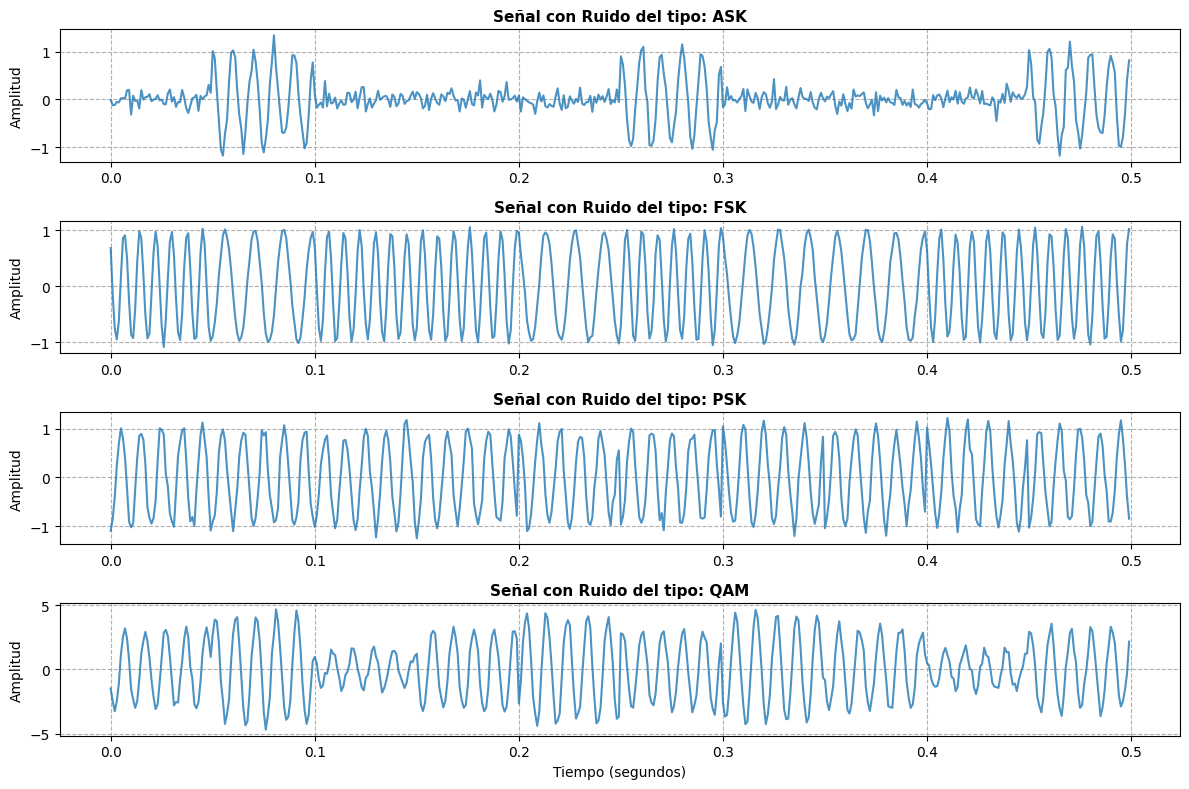

In [6]:

plt.figure(figsize=(12, 8))
for idx, tipo in enumerate(modulaciones):
    plt.subplot(4, 1, idx + 1)
    indice_muestra = idx * 1000
    plt.plot(t, X[indice_muestra], color='tab:blue', alpha=0.8)
    plt.title(f"Señal con Ruido del tipo: {tipo}", fontsize=11, fontweight='bold')
    plt.ylabel("Amplitud")
    plt.grid(True, linestyle='--')

plt.xlabel("Tiempo (segundos)")
plt.tight_layout()
plt.show()


In [7]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("")
print("             FASE 1 COMPLETADA CON ÉXITO            ")
print("\n")
print(f" Para Entrenar la IA (80%): {X_train.shape[0]} señales guardadas en 'X_train'.")
print(f" Para Evaluar la IA (20%):   {X_test.shape[0]} señales guardadas en 'X_test'.")



             FASE 1 COMPLETADA CON ÉXITO            


 Para Entrenar la IA (80%): 3200 señales guardadas en 'X_train'.
 Para Evaluar la IA (20%):   800 señales guardadas en 'X_test'.


In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense

# Definimos las dimensiones de manera directa para evitar errores de carga de variables
LONGITUD = 500  # Longitud fija de las señales generadas en el Paso 2
CANALES = 1     # 1 canal ya que son señales temporales unidimensionales

modelo = Sequential([
    Input(shape=(LONGITUD, CANALES)),
    Conv1D(filters=32, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Conv1D(filters=64, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(4, activation='softmax') # 4 neuronas (una por cada tipo de modulación)
])

In [9]:
# Compilación del modelo
modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Mostramos el resumen de la arquitectura de la red
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 498, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 249, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 247, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 123, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7872)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       503,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 510,468 (1.95 MB)

 Trainable params: 510,468 (1.95 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
modelo.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [11]:
# Aseguramos que el modelo esté compilado con la pérdida correcta para etiquetas de tipo entero
modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Iniciamos el entrenamiento
historial = modelo.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=20,
    batch_size=32
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.9334 - loss: 0.1950 - val_accuracy: 1.0000 - val_loss: 0.0170
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9994 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 1.0000 - loss: 5.0383e-04 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 1.0000 - loss: 4.6479e-04 - val_accuracy: 1.0000 - val_loss: 8.6283e-04
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 1.0000 - loss: 2.5569e-04 - val_accuracy: 1.0000 - val_loss: 6.7594e-04
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 1.0000 - loss: 1.4182e-04 - val_accuracy: 1.0000 - val_loss: 8.7721e-04
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 1.00

In [12]:
modelo.save('modelo_modulaciones.keras')


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


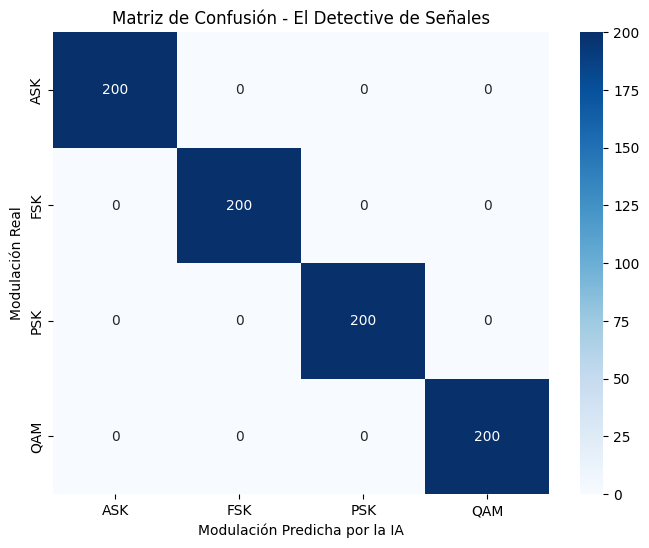

              precision    recall  f1-score   support

         ASK       1.00      1.00      1.00       200
         FSK       1.00      1.00      1.00       200
         PSK       1.00      1.00      1.00       200
         QAM       1.00      1.00      1.00       200

    accuracy                           1.00       800
   macro avg       1.00      1.00      1.00       800
weighted avg       1.00      1.00      1.00       800



In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Obtener predicciones del modelo entrenado en Fase 2 (Corregido 'model' por 'modelo')
y_pred_probs = modelo.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# Convertir y_test si está en formato One-Hot Encoding
if len(y_test.shape) > 1 and y_test.shape[1] > 1:
    y_true = np.argmax(y_test, axis=1)
else:
    y_true = y_test

# 2. Generar Matriz de Confusión
clases = ['ASK', 'FSK', 'PSK', 'QAM']
cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases, yticklabels=clases)

plt.title('Matriz de Confusión - El Detective de Señales')
plt.xlabel('Modulación Predicha por la IA')
plt.ylabel('Modulación Real')
plt.show()

# Imprimir métricas detalladas por clase
print(classification_report(y_true, y_pred_classes, target_names=clases))

SNR: -15 dB -> Precisión: 30.38%
SNR: -10 dB -> Precisión: 65.50%
SNR:  -5 dB -> Precisión: 89.25%
SNR:   0 dB -> Precisión: 99.62%
SNR:   5 dB -> Precisión: 99.75%
SNR:  10 dB -> Precisión: 100.00%
SNR:  15 dB -> Precisión: 100.00%
SNR:  20 dB -> Precisión: 100.00%


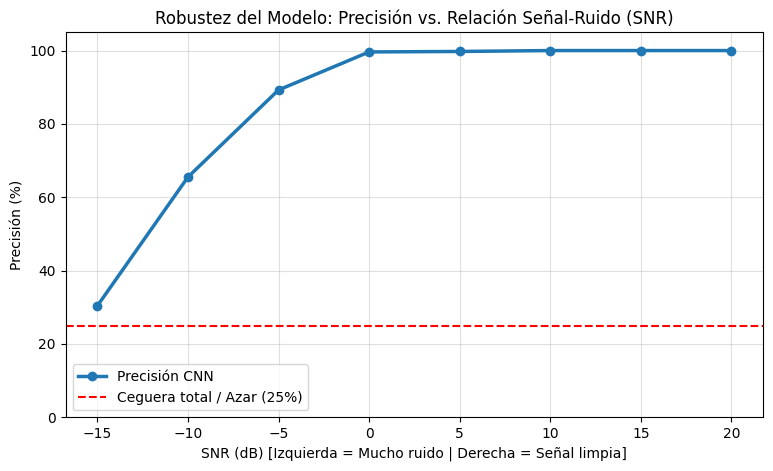

In [14]:
def agregar_awgn(senal, snr_db):
    # Calcula potencia de la señal y añade ruido según el SNR en dB
    potencia_senal = np.mean(np.abs(senal)**2)
    snr_lineal = 10**(snr_db / 10.0)
    potencia_ruido = potencia_senal / snr_lineal
    ruido = np.sqrt(potencia_ruido) * np.random.randn(*senal.shape)
    return senal + ruido

niveles_snr = [-15, -10, -5, 0, 5, 10, 15, 20]
precisiones = []

for snr in niveles_snr:
    # Aplica el nivel de ruido específico al conjunto de prueba
    X_test_ruido = np.array([agregar_awgn(x, snr) for x in X_test])

    # Evaluar precisión
    pred = np.argmax(modelo.predict(X_test_ruido, verbose=0), axis=1)
    acc = np.mean(pred == y_true) * 100
    precisiones.append(acc)
    print(f"SNR: {snr:3d} dB -> Precisión: {acc:.2f}%")

# Graficar rendimiento (Paso 3.3)
plt.figure(figsize=(9, 5))
plt.plot(niveles_snr, precisiones, marker='o', linewidth=2.5, color='#1f77b4', label='Precisión CNN')
plt.axhline(y=25, color='red', linestyle='--', label='Ceguera total / Azar (25%)')
plt.title('Robustez del Modelo: Precisión vs. Relación Señal-Ruido (SNR)')
plt.xlabel('SNR (dB) [Izquierda = Mucho ruido | Derecha = Señal limpia]')
plt.ylabel('Precisión (%)')
plt.ylim(0, 105)
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

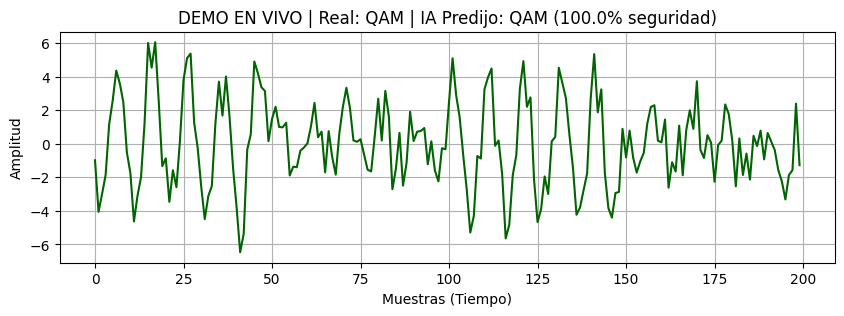

In [16]:
# Seleccionar una señal al azar del conjunto de prueba
idx = np.random.randint(0, len(X_test))
muestra = X_test[idx]
etiqueta_real = clases[y_true[idx]]

# Predicción de la IA (Corregido 'model' por 'modelo')
probabilidades = modelo.predict(np.expand_dims(muestra, axis=0), verbose=0)[0]
prediccion_ia = clases[np.argmax(probabilidades)]
confianza = np.max(probabilidades) * 100

# Mostrar resultado visual
plt.figure(figsize=(10, 3))
plt.plot(muestra.flatten()[:200], color='darkgreen')
plt.title(f"DEMO EN VIVO | Real: {etiqueta_real} | IA Predijo: {prediccion_ia} ({confianza:.1f}% seguridad)")
plt.xlabel("Muestras (Tiempo)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.show()